In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

BASE = (
    Path("expirement_v2")
    if Path("expirement_v2/data").is_dir()
    else Path(".")
)

bundle = joblib.load(BASE / "models/chl_forecast_1_4_7d.joblib")
prepared = xr.open_dataset(
    BASE / "data/processed/malta_forecast_prepared.nc"
)

predictor_names = bundle["feature_names"]

for coordinate in ["latitude", "longitude"]:
    np.testing.assert_array_equal(
        prepared[coordinate].values,
        bundle["model_mask"][coordinate].values,
    )

print(f"Horizons: {bundle['forecast_horizons_days']}")
print(f"Issue time: {bundle['forecast_issue_time_utc']} UTC")
display(prepared[predictor_names])

Horizons: [1, 4, 7]
Issue time: 20:30 UTC


<xarray.Dataset> Size: 353MB
Dimensions:              (time: 1461, latitude: 133, longitude: 101)
Coordinates:
  * time                 (time) datetime64[ns] 12kB 2022-01-01 ... 2025-12-31
  * latitude             (latitude) float32 532B 35.55 35.56 ... 36.88 36.89
  * longitude            (longitude) float32 404B 13.91 13.92 ... 15.18 15.19
Data variables:
    season_sin           (time) float32 6kB ...
    season_cos           (time) float32 6kB ...
    chl_latest           (time, latitude, longitude) float32 79MB ...
    chl_age_days         (time, latitude, longitude) float32 79MB ...
    chl_mean_7d          (time, latitude, longitude) float32 79MB ...
    chl_observations_7d  (time, latitude, longitude) uint8 20MB ...
    latitude_deg         (latitude) float32 532B ...
    longitude_deg        (longitude) float32 404B ...
    sst_c                (time, latitude, longitude) float32 79MB ...
    sst_observed         (time, latitude, longitude) uint8 20MB ...
Attributes:
    time_meaning:              Forecast issue date
    forecast_issue_time_utc:   20:30
    feature_names_json:        ["season_sin", "season_cos", "chl_latest", "ch...
    forecast_horizons_days:    [1 4 7]
    availability_basis:        Nominal NRT delivery schedules applied to MY o...
    target_source:             Observed L3 chlorophyll
    training_period:           2022–2023
    validation_period:         2024
    test_period:               2025
    source_observations_file:  malta_daily_observations.nc

In [2]:
ISSUE_DATE = "2025-02-15"

day = prepared[predictor_names].sel(time=ISSUE_DATE)
mask = bundle["model_mask"].values == 1

lat_idx, lon_idx = np.nonzero(mask)

X_day = (
    day.isel(
        latitude=xr.DataArray(lat_idx, dims="pixel"),
        longitude=xr.DataArray(lon_idx, dims="pixel"),
    )
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe()[predictor_names]
    .astype("float32")
)

forecast_horizons = bundle["forecast_horizons_days"]
forecast_values = np.full(
    (len(forecast_horizons), *mask.shape),
    np.nan,
    dtype="float32",
)

for index, horizon in enumerate(forecast_horizons):
    forecast_values[index, lat_idx, lon_idx] = (
        10.0 ** bundle["models"][horizon].predict(X_day)
    )

forecast = xr.Dataset(
    {
        "chl_forecast": (
            ("horizon", "latitude", "longitude"), forecast_values
        )
    },
    coords={
        "horizon": forecast_horizons,
        "latitude": prepared.latitude,
        "longitude": prepared.longitude,
        "target_date": (
            "horizon",
            [
                (pd.Timestamp(ISSUE_DATE) + pd.Timedelta(days=h)).to_datetime64()
                for h in forecast_horizons
            ],
        ),
    },
)

forecast["chl_forecast"].attrs["units"] = bundle["target_units"]
forecast.attrs["issue_date"] = ISSUE_DATE
forecast.attrs["issue_time_utc"] = bundle["forecast_issue_time_utc"]

display(forecast)

<xarray.Dataset> Size: 162kB
Dimensions:       (horizon: 3, latitude: 133, longitude: 101)
Coordinates:
  * horizon       (horizon) int64 24B 1 4 7
    target_date   (horizon) datetime64[us] 24B 2025-02-16 2025-02-19 2025-02-22
  * latitude      (latitude) float32 532B 35.55 35.56 35.57 ... 36.88 36.89
  * longitude     (longitude) float32 404B 13.91 13.92 13.93 ... 15.18 15.19
Data variables:
    chl_forecast  (horizon, latitude, longitude) float32 161kB 0.09511 ... 0....
Attributes:
    issue_date:      2025-02-15
    issue_time_utc:  20:30

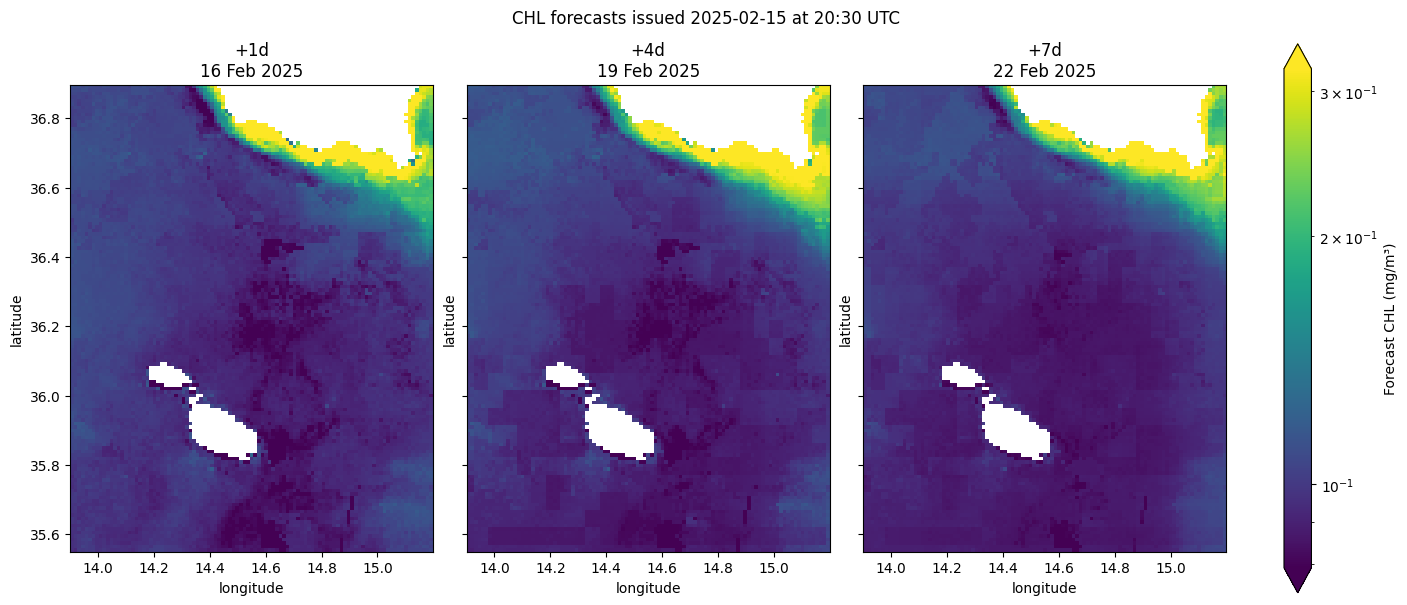

In [3]:
vmin, vmax = np.nanpercentile(
    forecast["chl_forecast"].values, [2, 98]
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 6),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, horizon, target_date in zip(
    axes,
    forecast.horizon.values,
    forecast.target_date.to_index(),
):
    image = forecast["chl_forecast"].sel(
        horizon=horizon
    ).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="viridis",
        norm=LogNorm(vmin=vmin, vmax=vmax),
        add_colorbar=False,
    )

    ax.set_title(f"+{horizon}d\n{target_date:%d %b %Y}")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(forecast.latitude.mean())))
    )

fig.colorbar(
    image, ax=axes.tolist(),
    label="Forecast CHL (mg/m³)", extend="both",
)

fig.suptitle(
    f"CHL forecasts issued {ISSUE_DATE} "
    f"at {bundle['forecast_issue_time_utc']} UTC"
)
plt.show()

In [4]:
observed_maps = xr.concat(
    [
        prepared[f"chl_target_{int(h)}d"]
        .sel(time=ISSUE_DATE, drop=True)
        .where(bundle["model_mask"] == 1)
        for h in forecast.horizon.values
    ],
    dim=forecast.horizon,
).rename("chl_observed")

observed_maps = observed_maps.assign_coords(
    target_date=forecast.target_date
)

display(
    observed_maps.count(dim=["latitude", "longitude"])
    .to_dataframe(name="Observed pixels")
)

,target_date,Observed pixels
horizon,,
1,2025-02-16,10610
4,2025-02-19,8746
7,2025-02-22,8857


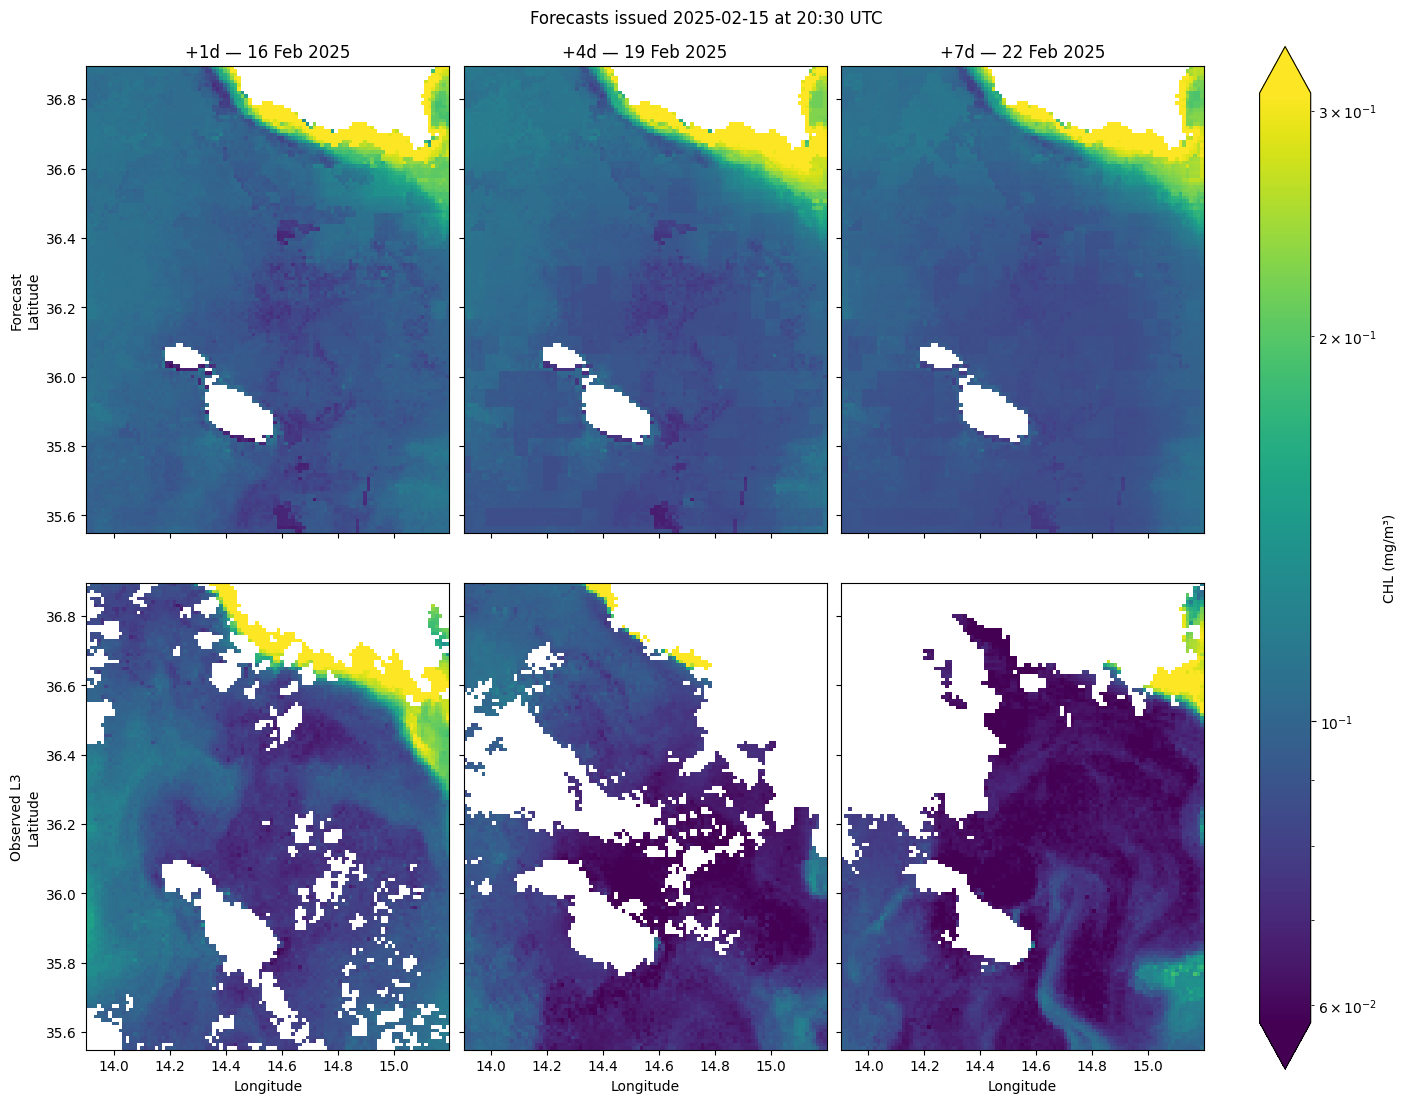

In [5]:
combined_values = np.concatenate([
    forecast["chl_forecast"].values.ravel(),
    observed_maps.values.ravel(),
])
vmin, vmax = np.nanpercentile(combined_values, [2, 98])
norm = LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(
    2, 3, figsize=(14, 11),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for row, (label, field) in enumerate([
    ("Forecast", forecast["chl_forecast"]),
    ("Observed L3", observed_maps),
]):
    for col, (horizon, target_date) in enumerate(zip(
        forecast.horizon.values,
        forecast.target_date.to_index(),
    )):
        ax = axes[row, col]

        image = field.sel(horizon=horizon).plot.pcolormesh(
            ax=ax,
            x="longitude",
            y="latitude",
            cmap="viridis",
            norm=norm,
            add_colorbar=False,
        )

        ax.set_title(
            f"+{horizon}d — {target_date:%d %b %Y}" if row == 0 else ""
        )
        ax.set_xlabel("Longitude" if row == 1 else "")
        ax.set_ylabel(f"{label}\nLatitude" if col == 0 else "")
        ax.set_aspect(
            1 / np.cos(np.deg2rad(float(forecast.latitude.mean())))
        )

fig.colorbar(
    image, ax=axes.ravel().tolist(),
    label="CHL (mg/m³)", extend="both",
)
fig.suptitle(
    f"Forecasts issued {forecast.attrs['issue_date']} "
    f"at {forecast.attrs['issue_time_utc']} UTC"
)
plt.show()

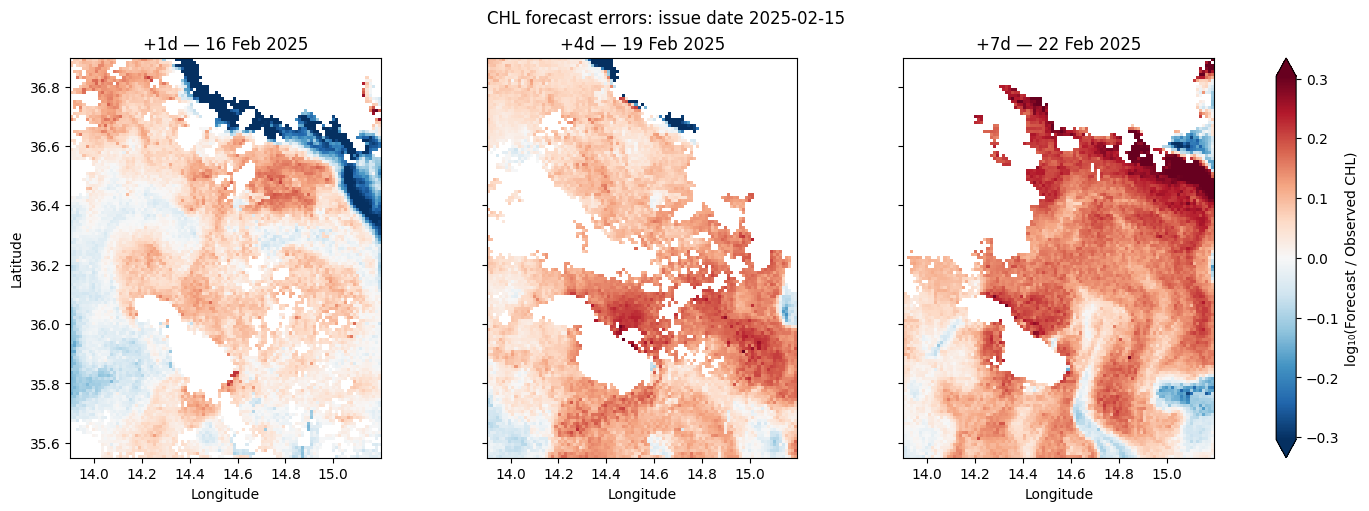

In [6]:
paired = (
    np.isfinite(forecast["chl_forecast"])
    & np.isfinite(observed_maps)
    & (forecast["chl_forecast"] > 0)
    & (observed_maps > 0)
)

log_ratio = np.log10(
    forecast["chl_forecast"].where(paired)
    / observed_maps.where(paired)
)

# Shared, symmetric colour scale; extreme values remain visible
# through the colour bar's extension triangles.
limit = max(
    float(np.nanpercentile(np.abs(log_ratio.values), 98)),
    0.01,
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, horizon, target_date in zip(
    axes, forecast.horizon.values, forecast.target_date.to_index()
):
    image = log_ratio.sel(horizon=horizon).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        add_colorbar=False,
    )
    ax.set_title(f"+{horizon}d — {target_date:%d %b %Y}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude" if ax is axes[0] else "")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(forecast.latitude.mean())))
    )

fig.colorbar(
    image,
    ax=axes.tolist(),
    label="log₁₀(Forecast / Observed CHL)",
    extend="both",
)
fig.suptitle(f"CHL forecast errors: issue date {ISSUE_DATE}")
plt.show()

In [7]:
persistence_map = (
    prepared["chl_latest"]
    .sel(time=ISSUE_DATE)
    .transpose("latitude", "longitude")
    .values
)

rows = []

for horizon in forecast.horizon.values:
    actual = observed_maps.sel(horizon=horizon).values
    predicted = forecast["chl_forecast"].sel(horizon=horizon).values

    common = (
        np.isfinite(actual) & (actual > 0)
        & np.isfinite(predicted) & (predicted > 0)
        & np.isfinite(persistence_map) & (persistence_map > 0)
    )

    y = actual[common].astype("float64")

    for method, field in [
        ("Persistence", persistence_map),
        ("Forecast model", predicted),
    ]:
        p = field[common].astype("float64")
        error = p - y
        log_error = np.log10(p / y)

        rows.append({
            "Horizon": f"+{int(horizon)}d",
            "Method": method,
            "Scored pixels": len(y),
            "Bias (mg/m³)": error.mean(),
            "MAE (mg/m³)": np.abs(error).mean(),
            "RMSE (log10)": np.sqrt(np.mean(log_error**2)),
            "Median relative error (%)":
                np.median(100 * np.abs(error) / y),
        })

example_scores = pd.DataFrame(rows).set_index(["Horizon", "Method"])

display(example_scores.style.format({
    "Scored pixels": "{:,.0f}",
    "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}",
}))

In [ ]:
ISSUE_DATE = "2025-08-15"

In [8]:
ISSUE_DATE = "2025-08-15"

day = prepared[bundle["feature_names"]].sel(time=ISSUE_DATE)

mask = bundle["model_mask"].values == 1
lat_idx, lon_idx = np.nonzero(mask)
horizons = bundle["forecast_horizons_days"]

X_day = (
    day.isel(
        latitude=xr.DataArray(lat_idx, dims="pixel"),
        longitude=xr.DataArray(lon_idx, dims="pixel"),
    )
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe()[bundle["feature_names"]]
    .astype("float32")
)

values = np.full(
    (len(horizons), *mask.shape), np.nan, dtype="float32"
)

for i, horizon in enumerate(horizons):
    values[i, lat_idx, lon_idx] = (
        10.0 ** bundle["models"][horizon].predict(X_day)
    )

forecast = xr.Dataset(
    {
        "chl_forecast": (
            ("horizon", "latitude", "longitude"),
            values,
        )
    },
    coords={
        "horizon": horizons,
        "latitude": prepared.latitude,
        "longitude": prepared.longitude,
        "target_date": (
            "horizon",
            [
                (
                    pd.Timestamp(ISSUE_DATE)
                    + pd.Timedelta(days=int(h))
                ).to_datetime64()
                for h in horizons
            ],
        ),
    },
    attrs={
        "issue_date": ISSUE_DATE,
        "issue_time_utc": bundle["forecast_issue_time_utc"],
    },
)

forecast["chl_forecast"].attrs["units"] = bundle["target_units"]

observed_maps = xr.concat(
    [
        prepared[f"chl_target_{int(h)}d"]
        .sel(time=ISSUE_DATE, drop=True)
        .where(bundle["model_mask"] == 1)
        for h in horizons
    ],
    dim=forecast.horizon,
).rename("chl_observed")

observed_maps = observed_maps.assign_coords(
    target_date=forecast.target_date
)

display(pd.DataFrame({
    "Horizon": [f"+{h}d" for h in horizons],
    "Target date": forecast.target_date.to_index().strftime("%Y-%m-%d"),
    "Observed pixels": observed_maps.notnull()
        .sum(("latitude", "longitude")).values,
}).set_index("Horizon"))

,Target date,Observed pixels
Horizon,,
+1d,2025-08-16,8661
+4d,2025-08-19,11361
+7d,2025-08-22,5440


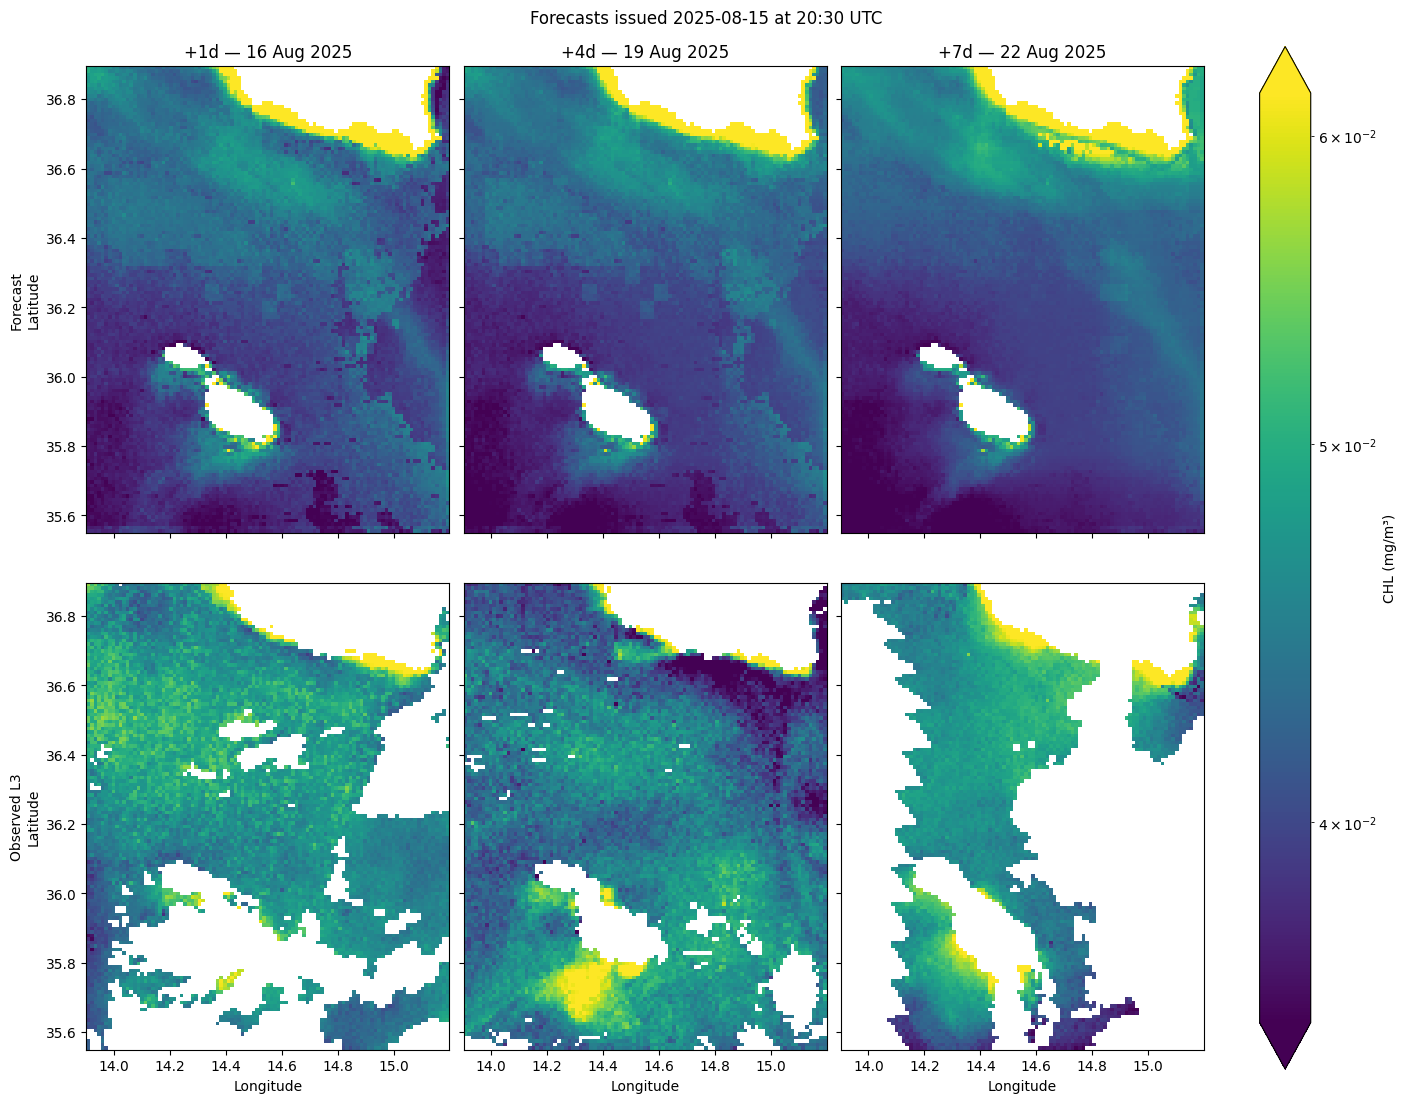

In [9]:
combined_values = np.concatenate([
    forecast["chl_forecast"].values.ravel(),
    observed_maps.values.ravel(),
])

positive_values = combined_values[
    np.isfinite(combined_values) & (combined_values > 0)
]
vmin, vmax = np.percentile(positive_values, [2, 98])
norm = LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(
    2, 3, figsize=(14, 11),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for row, (label, field) in enumerate([
    ("Forecast", forecast["chl_forecast"]),
    ("Observed L3", observed_maps),
]):
    for col, (horizon, target_date) in enumerate(zip(
        forecast.horizon.values,
        forecast.target_date.to_index(),
    )):
        ax = axes[row, col]

        image = field.sel(horizon=horizon).plot.pcolormesh(
            ax=ax,
            x="longitude",
            y="latitude",
            cmap="viridis",
            norm=norm,
            add_colorbar=False,
        )

        ax.set_title(
            f"+{int(horizon)}d — {target_date:%d %b %Y}"
            if row == 0 else ""
        )
        ax.set_xlabel("Longitude" if row == 1 else "")
        ax.set_ylabel(f"{label}\nLatitude" if col == 0 else "")
        ax.set_aspect(
            1 / np.cos(np.deg2rad(float(forecast.latitude.mean())))
        )

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="CHL (mg/m³)",
    extend="both",
)

fig.suptitle(
    f"Forecasts issued {ISSUE_DATE} "
    f"at {forecast.attrs['issue_time_utc']} UTC"
)

plt.show()

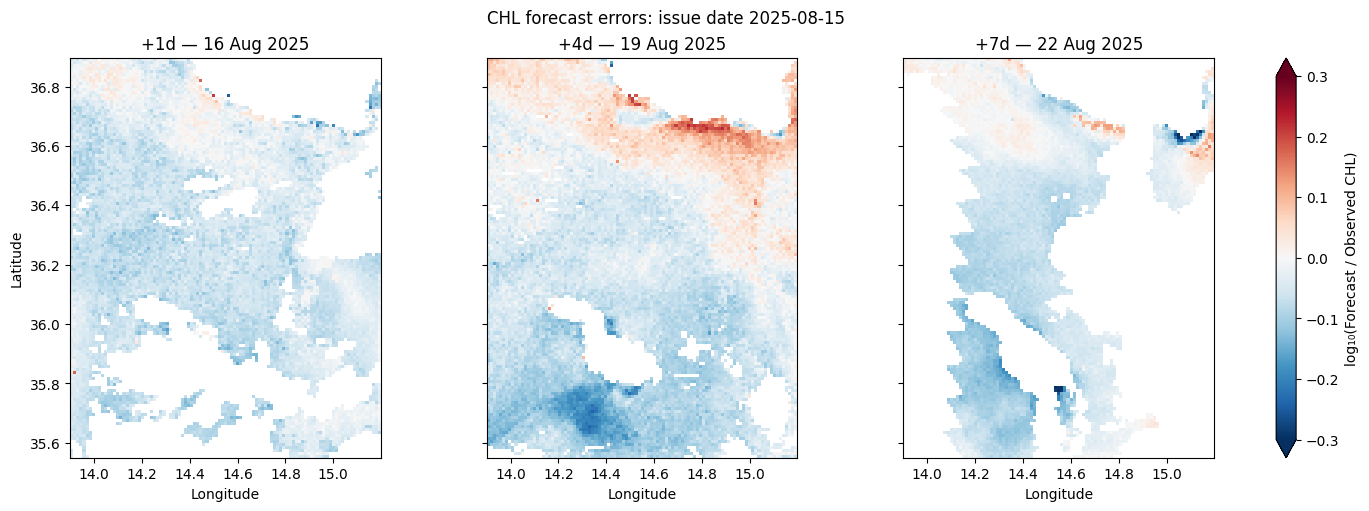

In [10]:
paired = (
    np.isfinite(forecast["chl_forecast"])
    & np.isfinite(observed_maps)
    & (forecast["chl_forecast"] > 0)
    & (observed_maps > 0)
)

log_ratio = np.log10(
    forecast["chl_forecast"].where(paired)
    / observed_maps.where(paired)
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, horizon, target_date in zip(
    axes,
    forecast.horizon.values,
    forecast.target_date.to_index(),
):
    image = log_ratio.sel(horizon=horizon).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="RdBu_r",
        vmin=-0.3,
        vmax=0.3,
        add_colorbar=False,
    )

    ax.set_title(f"+{int(horizon)}d — {target_date:%d %b %Y}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude" if ax is axes[0] else "")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(forecast.latitude.mean())))
    )

fig.colorbar(
    image,
    ax=axes.tolist(),
    label="log₁₀(Forecast / Observed CHL)",
    extend="both",
)
fig.suptitle(f"CHL forecast errors: issue date {ISSUE_DATE}")
plt.show()

In [11]:
persistence_map = (
    prepared["chl_latest"]
    .sel(time=ISSUE_DATE)
    .transpose("latitude", "longitude")
    .values
)

rows = []

for horizon in forecast.horizon.values:
    actual = observed_maps.sel(horizon=horizon).values
    predicted = forecast["chl_forecast"].sel(horizon=horizon).values

    common = (
        np.isfinite(actual) & (actual > 0)
        & np.isfinite(predicted) & (predicted > 0)
        & np.isfinite(persistence_map) & (persistence_map > 0)
    )
    y = actual[common].astype("float64")

    for method, field in [
        ("Persistence", persistence_map),
        ("Forecast model", predicted),
    ]:
        p = field[common].astype("float64")
        error = p - y
        log_error = np.log10(p / y)

        rows.append({
            "Horizon": f"+{int(horizon)}d",
            "Method": method,
            "Scored pixels": len(y),
            "Bias (mg/m³)": error.mean(),
            "MAE (mg/m³)": np.abs(error).mean(),
            "RMSE (log10)": np.sqrt(np.mean(log_error**2)),
            "Median relative error (%)":
                np.median(100 * np.abs(error) / y),
        })

example_scores = pd.DataFrame(rows).set_index(["Horizon", "Method"])

display(example_scores.style.format({
    "Scored pixels": "{:,.0f}",
    "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}",
}))

In [12]:
test_data = prepared.sel(
    time=slice("2025-01-01", "2025-12-24")
)

season_names = {
    "DJF": "Winter",
    "MAM": "Spring",
    "JJA": "Summer",
    "SON": "Autumn",
}

rows = []

for horizon in bundle["forecast_horizons_days"]:
    target = test_data[f"chl_target_{horizon}d"]

    valid = (
        np.isfinite(target)
        & (target > 0)
        & (bundle["model_mask"] == 1)
    )

    target_dates = test_data.time + np.timedelta64(int(horizon), "D")
    target_seasons = target_dates.dt.season

    for code, name in season_names.items():
        rows.append({
            "Horizon": f"+{horizon}d",
            "Target season": name,
            "Issue dates": int((target_seasons == code).sum().item()),
            "Valid target pixels": int(
                valid.where(target_seasons == code, False).sum().item()
            ),
        })

season_counts = pd.DataFrame(rows).set_index(
    ["Horizon", "Target season"]
)

display(season_counts.style.format({
    "Issue dates": "{:,.0f}",
    "Valid target pixels": "{:,.0f}",
}))

In [13]:
horizon = 1

target = test_data[f"chl_target_{horizon}d"].transpose(
    "time", "latitude", "longitude"
)

valid = (
    np.isfinite(target)
    & (target > 0)
    & (bundle["model_mask"] == 1)
)

positions = np.nonzero(valid.values)

indexers = {
    dim: xr.DataArray(indices, dims="sample")
    for dim, indices in zip(target.dims, positions)
}

X_test_1d = (
    test_data[bundle["feature_names"]]
    .isel(indexers)
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe()[bundle["feature_names"]]
    .astype("float32")
)

y_test_1d = target.values[positions].astype("float64")

persistence_test_1d = (
    X_test_1d["chl_latest"].to_numpy(dtype="float64")
)

prediction_test_1d = (
    10.0 ** bundle["models"][horizon].predict(X_test_1d)
)

target_dates = test_data.time + np.timedelta64(horizon, "D")
target_season_test_1d = target_dates.dt.season.values[positions[0]]

print(f"+1-day test predictions: {len(prediction_test_1d):,}")

+1-day test predictions: 2,837,210


In [14]:
def seasonal_comparison(actual, persistence, prediction, seasons):
    common = (
        np.isfinite(actual) & (actual > 0)
        & np.isfinite(persistence) & (persistence > 0)
        & np.isfinite(prediction) & (prediction > 0)
    )

    rows = []

    for code, name in season_names.items():
        selected = common & (seasons == code)
        y = actual[selected].astype("float64")

        for method, values in [
            ("Persistence", persistence),
            ("Forecast model", prediction),
        ]:
            p = values[selected].astype("float64")
            error = p - y
            log_error = np.log10(p / y)

            rows.append({
                "Target season": name,
                "Method": method,
                "Scored pixel-days": len(y),
                "Bias (mg/m³)": error.mean(),
                "MAE (mg/m³)": np.abs(error).mean(),
                "RMSE (mg/m³)": np.sqrt(np.mean(error**2)),
                "RMSE (log10)": np.sqrt(np.mean(log_error**2)),
                "Median relative error (%)":
                    np.median(100 * np.abs(error) / y),
            })

    return pd.DataFrame(rows).set_index(["Target season", "Method"])


seasonal_scores_1d = seasonal_comparison(
    y_test_1d,
    persistence_test_1d,
    prediction_test_1d,
    target_season_test_1d,
)

score_formats = {
    "Scored pixel-days": "{:,.0f}",
    "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (mg/m³)": "{:.4f}",
    "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}",
}

display(seasonal_scores_1d.style.format(score_formats))

In [15]:
def evaluate_test_horizon(horizon):
    target = test_data[f"chl_target_{horizon}d"].transpose(
        "time", "latitude", "longitude"
    )

    valid = (
        np.isfinite(target)
        & (target > 0)
        & (bundle["model_mask"] == 1)
    )

    positions = np.nonzero(valid.values)

    indexers = {
        dim: xr.DataArray(indices, dims="sample")
        for dim, indices in zip(target.dims, positions)
    }

    X = (
        test_data[bundle["feature_names"]]
        .isel(indexers)
        .drop_vars(["time", "latitude", "longitude"])
        .to_dataframe()[bundle["feature_names"]]
        .astype("float32")
    )

    actual = target.values[positions].astype("float64")
    persistence = X["chl_latest"].to_numpy(dtype="float64")
    prediction = 10.0 ** bundle["models"][horizon].predict(X)

    target_dates = test_data.time + np.timedelta64(int(horizon), "D")
    seasons = target_dates.dt.season.values[positions[0]]

    return seasonal_comparison(
        actual, persistence, prediction, seasons
    )


seasonal_scores_4d = evaluate_test_horizon(4)

display(seasonal_scores_4d.style.format(score_formats))

In [16]:
seasonal_scores_7d = evaluate_test_horizon(7)

display(seasonal_scores_7d.style.format(score_formats))

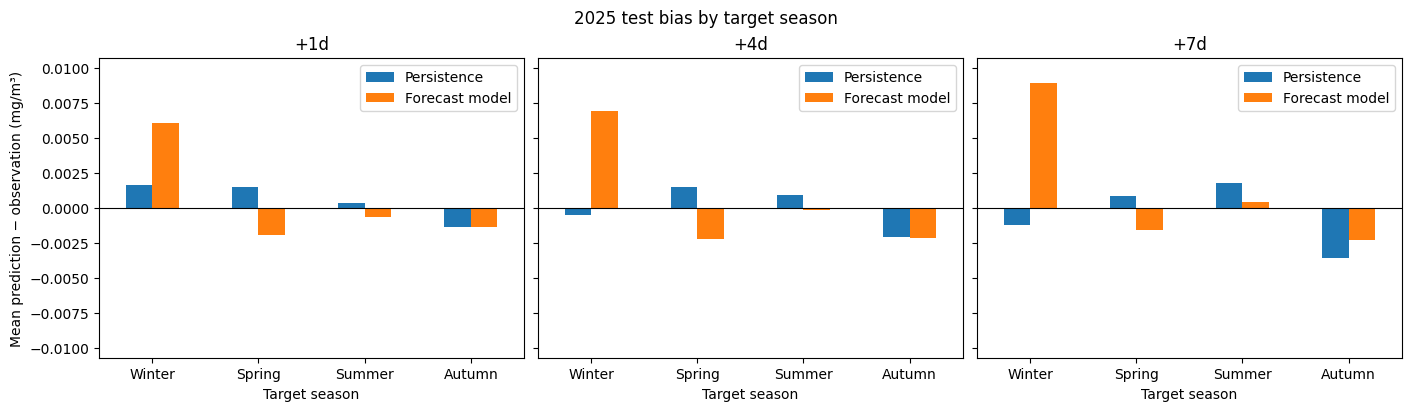

In [17]:
combined_seasonal_scores = pd.concat(
    {
        "+1d": seasonal_scores_1d,
        "+4d": seasonal_scores_4d,
        "+7d": seasonal_scores_7d,
    },
    names=["Horizon"],
)

limit = (
    combined_seasonal_scores["Bias (mg/m³)"].abs().max() * 1.2
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4),
    sharey=True,
    constrained_layout=True,
)

for ax, horizon in zip(axes, ["+1d", "+4d", "+7d"]):
    bias = (
        combined_seasonal_scores
        .xs(horizon, level="Horizon")["Bias (mg/m³)"]
        .unstack("Method")
        .reindex(
            index=list(season_names.values()),
            columns=["Persistence", "Forecast model"],
        )
    )

    bias.plot.bar(ax=ax, color=["tab:blue", "tab:orange"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(horizon)
    ax.set_xlabel("Target season")
    ax.set_ylim(-limit, limit)
    ax.tick_params(axis="x", rotation=0)
    ax.legend()

axes[0].set_ylabel("Mean prediction − observation (mg/m³)")
fig.suptitle("2025 test bias by target season")
plt.show()

In [18]:
def winter_error_maps(horizon):
    target_dates = test_data.time + np.timedelta64(int(horizon), "D")
    winter = test_data.isel(
        time=np.flatnonzero(target_dates.dt.season.values == "DJF")
    )

    target = winter[f"chl_target_{horizon}d"].transpose(
        "time", "latitude", "longitude"
    )

    valid = (
        np.isfinite(target)
        & (target > 0)
        & (bundle["model_mask"] == 1)
    )
    positions = np.nonzero(valid.values)

    indexers = {
        dim: xr.DataArray(indices, dims="sample")
        for dim, indices in zip(target.dims, positions)
    }

    X = (
        winter[bundle["feature_names"]]
        .isel(indexers)
        .drop_vars(["time", "latitude", "longitude"])
        .to_dataframe()[bundle["feature_names"]]
        .astype("float32")
    )

    actual = target.values[positions].astype("float64")
    predicted = 10.0 ** bundle["models"][horizon].predict(X)
    scored = np.isfinite(predicted) & (predicted > 0)

    shape = bundle["model_mask"].shape
    pixel_index = np.ravel_multi_index(
        (positions[1][scored], positions[2][scored]), shape
    )

    counts = np.bincount(pixel_index, minlength=np.prod(shape))
    error_sum = np.bincount(
        pixel_index,
        weights=predicted[scored] - actual[scored],
        minlength=np.prod(shape),
    )

    mean_error = np.divide(
        error_sum,
        counts,
        out=np.full(counts.shape, np.nan),
        where=counts > 0,
    )

    return xr.Dataset(
        {
            "mean_error": (
                ("latitude", "longitude"),
                mean_error.reshape(shape),
            ),
            "scored_days": (
                ("latitude", "longitude"),
                counts.reshape(shape).astype("int32"),
            ),
        },
        coords={
            "latitude": test_data.latitude,
            "longitude": test_data.longitude,
        },
        attrs={"horizon_days": int(horizon), "target_season": "Winter"},
    )


winter_maps_1d = winter_error_maps(1)

print(
    "Scored winter pixel-days:",
    f"{int(winter_maps_1d.scored_days.sum().item()):,}",
)

Scored winter pixel-days: 518,238


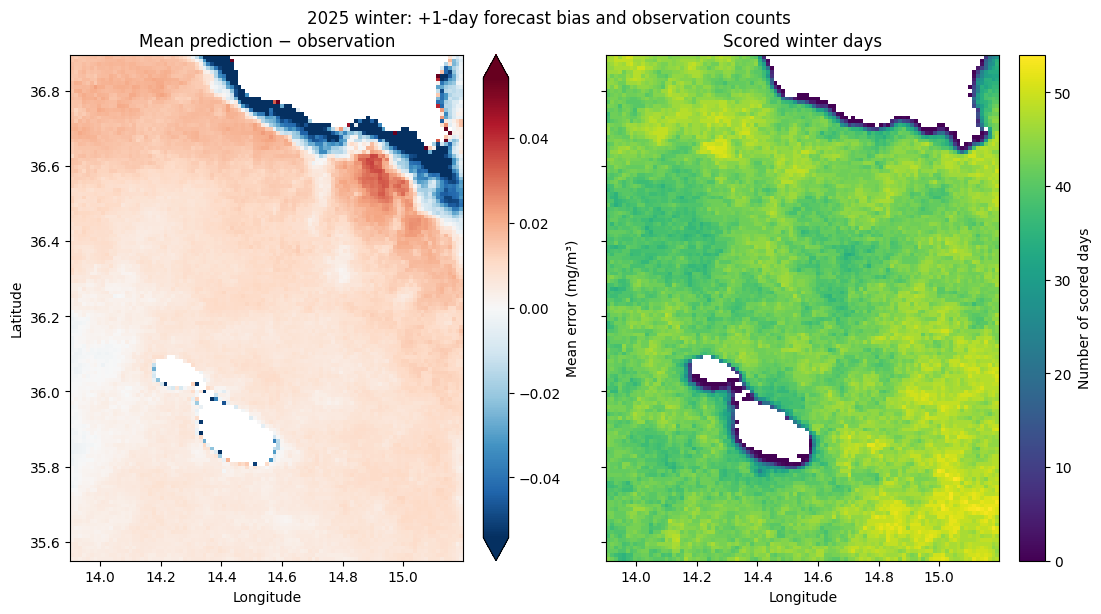

In [19]:
bias = winter_maps_1d["mean_error"]
counts = winter_maps_1d["scored_days"].where(
    bundle["model_mask"] == 1
)

# Symmetric scale; colour-bar extensions indicate clipped extremes.
limit = max(
    float(np.nanpercentile(np.abs(bias.values), 98)),
    1e-6,
)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 6),
    sharex=True, sharey=True,
    constrained_layout=True,
)

bias_image = bias.plot.pcolormesh(
    ax=axes[0],
    x="longitude",
    y="latitude",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    add_colorbar=False,
)

count_image = counts.plot.pcolormesh(
    ax=axes[1],
    x="longitude",
    y="latitude",
    cmap="viridis",
    vmin=0,
    vmax=float(counts.max().item()),
    add_colorbar=False,
)

axes[0].set_title("Mean prediction − observation")
axes[1].set_title("Scored winter days")

for i, ax in enumerate(axes):
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude" if i == 0 else "")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(test_data.latitude.mean())))
    )

fig.colorbar(
    bias_image, ax=axes[0],
    label="Mean error (mg/m³)", extend="both",
)
fig.colorbar(
    count_image, ax=axes[1],
    label="Number of scored days",
)

fig.suptitle("2025 winter: +1-day forecast bias and observation counts")
plt.show()

In [20]:
winter_maps_4d = winter_error_maps(4)
winter_maps_7d = winter_error_maps(7)

for horizon, maps in [
    (1, winter_maps_1d),
    (4, winter_maps_4d),
    (7, winter_maps_7d),
]:
    print(
        f"+{horizon}d: "
        f"{int(maps.scored_days.sum().item()):,} scored winter pixel-days"
    )

+1d: 518,238 scored winter pixel-days
+4d: 527,907 scored winter pixel-days
+7d: 533,108 scored winter pixel-days


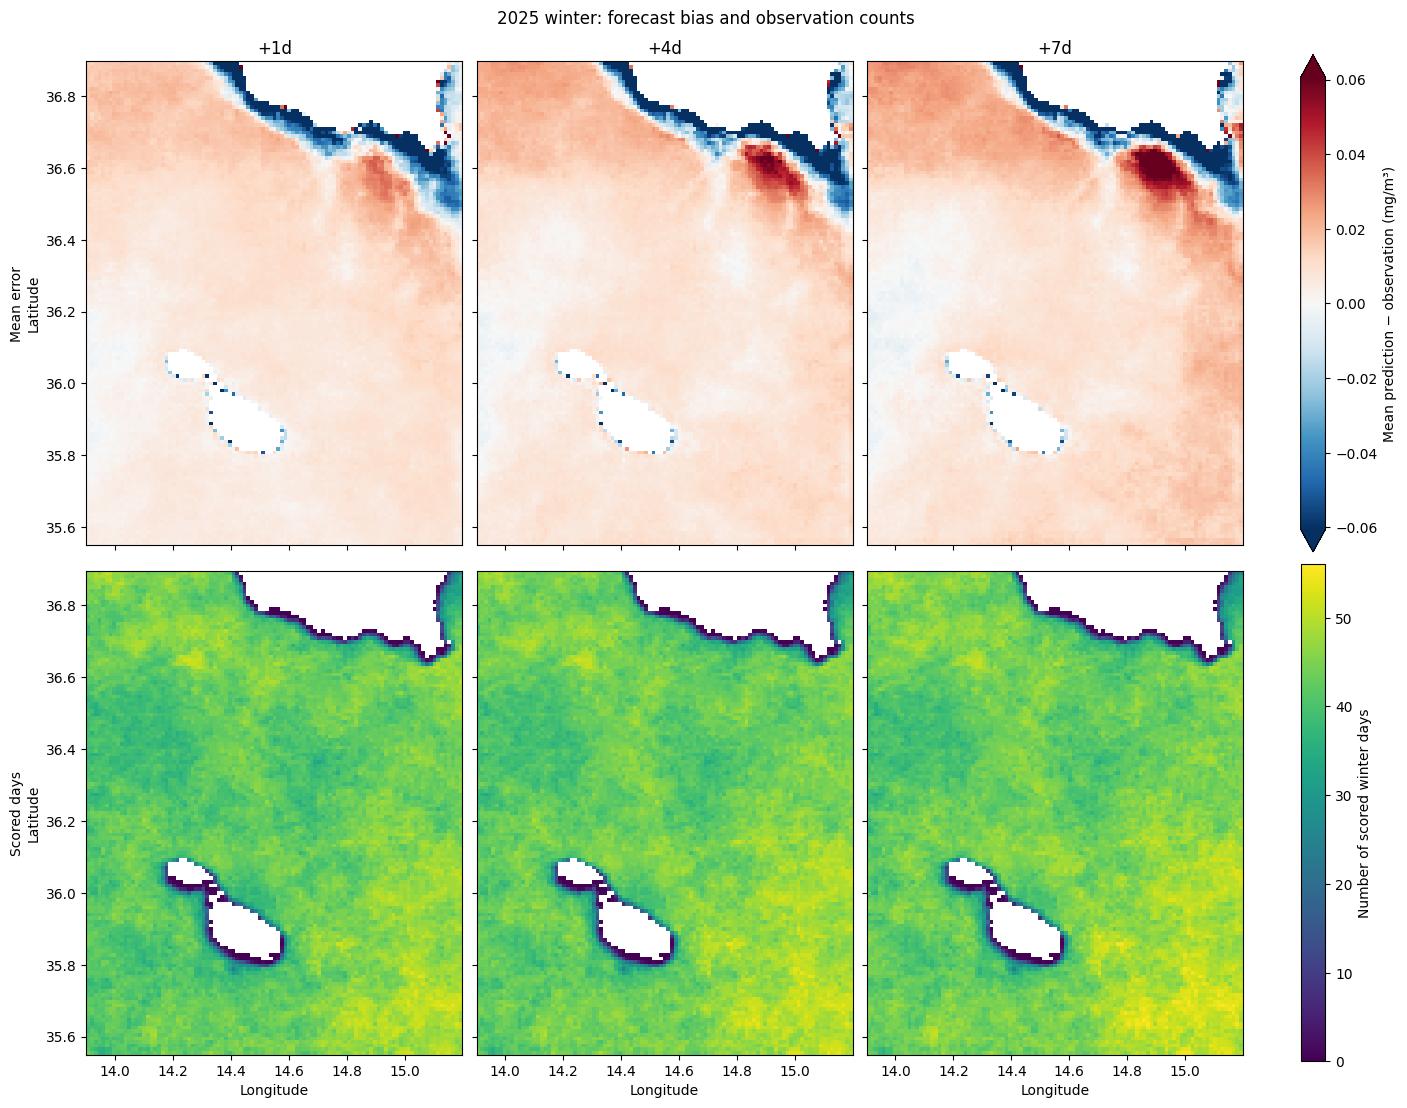

In [21]:
winter_maps = {
    1: winter_maps_1d,
    4: winter_maps_4d,
    7: winter_maps_7d,
}

all_bias = np.concatenate([
    maps["mean_error"].values.ravel()
    for maps in winter_maps.values()
])
limit = max(float(np.nanpercentile(np.abs(all_bias), 98)), 1e-6)

max_count = max(
    int(maps["scored_days"].max().item())
    for maps in winter_maps.values()
)

fig, axes = plt.subplots(
    2, 3, figsize=(14, 11),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for col, (horizon, maps) in enumerate(winter_maps.items()):
    bias_image = maps["mean_error"].plot.pcolormesh(
        ax=axes[0, col],
        x="longitude",
        y="latitude",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        add_colorbar=False,
    )

    count_image = maps["scored_days"].where(
        bundle["model_mask"] == 1
    ).plot.pcolormesh(
        ax=axes[1, col],
        x="longitude",
        y="latitude",
        cmap="viridis",
        vmin=0,
        vmax=max_count,
        add_colorbar=False,
    )

    axes[0, col].set_title(f"+{horizon}d")
    axes[1, col].set_title("")

    for row in range(2):
        ax = axes[row, col]
        ax.set_xlabel("Longitude" if row == 1 else "")
        ax.set_ylabel(
            ("Mean error\nLatitude" if row == 0 else
             "Scored days\nLatitude")
            if col == 0 else ""
        )
        ax.set_aspect(
            1 / np.cos(np.deg2rad(float(test_data.latitude.mean())))
        )

fig.colorbar(
    bias_image,
    ax=axes[0, :].tolist(),
    label="Mean prediction − observation (mg/m³)",
    extend="both",
)
fig.colorbar(
    count_image,
    ax=axes[1, :].tolist(),
    label="Number of scored winter days",
)

fig.suptitle("2025 winter: forecast bias and observation counts")
plt.show()

In [22]:
output_dir = BASE / "data" / "processed" / "forecast_diagnostics_2025"
output_dir.mkdir(parents=True, exist_ok=True)

# Seasonal metrics in a portable, readable format.
combined_seasonal_scores.reset_index().to_json(
    output_dir / "seasonal_scores_2025.json",
    orient="records",
    indent=2,
    double_precision=10,
)

# Spatial diagnostics for all three horizons.
winter_diagnostics = xr.concat(
    [winter_maps_1d, winter_maps_4d, winter_maps_7d],
    dim=xr.IndexVariable("horizon", [1, 4, 7]),
    combine_attrs="drop",
)

winter_diagnostics["model_mask"] = bundle["model_mask"].astype("uint8")

winter_diagnostics["mean_error"].attrs = {
    "units": "milligram m^-3",
    "description": "Mean forecast minus observed L3 CHL on scored days",
}
winter_diagnostics["scored_days"].attrs = {
    "units": "days",
    "description": "Number of valid forecast-observation pairs per pixel",
}
winter_diagnostics.attrs = {
    "test_year": 2025,
    "target_season": "Winter (December–February)",
    "forecast_issue_time_utc": bundle["forecast_issue_time_utc"],
    "availability_basis": bundle["availability_basis"],
}

winter_diagnostics.to_netcdf(
    output_dir / "winter_bias_maps_2025.nc",
    encoding={
        name: {"zlib": True, "complevel": 4}
        for name in winter_diagnostics.data_vars
    },
)

# Save the six-panel winter figure from the previous cell.
fig.savefig(
    output_dir / "winter_bias_and_counts_2025.png",
    dpi=200,
    bbox_inches="tight",
)

print(f"Saved diagnostics to: {output_dir.resolve()}")

Saved diagnostics to: C:\GIT\mcast.pages.chloropyll_prediction_v2\experiment_v2\data\processed\forecast_diagnostics_2025
